#                                    BEATS POR SEGUNDO 

>Proyecto
>
>Predecir los beats por segundo de un determinado grupo de canciones tomando como referencia el dataset dado.

>Descripción
>
>El conjunto de datos obtenido contiene la predicción de los beats por segundo, por tal motivo, el aprendizaje es supervisado.

In [1]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, make_scorer, r2_score, mean_squared_error
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import mutual_info_regression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

In [2]:
#Carga de los datos y creación de la copia de seguridad del dataset
data = pd.read_csv("C:/Users/PcDroide/Documents/MasterUE_IA/Machine_Learning/Proyecto/Proyecto_BPS_Files/Datasets/train.csv")
data_set_original = data.copy()



**Análisis de los datos**



In [3]:
#Verificación de datos falatantes y nulos
vacio = data.isna().sum()
nulo = data.isnull().sum()
print(f"La cantidad de líneas vacías por columna es: \n{vacio}")
print(f"\nLa cantidad de valores nulos es: \n{nulo}")

La cantidad de líneas vacías por columna es: 
id                           0
RhythmScore                  0
AudioLoudness                0
VocalContent                 0
AcousticQuality              0
InstrumentalScore            0
LivePerformanceLikelihood    0
MoodScore                    0
TrackDurationMs              0
Energy                       0
BeatsPerMinute               0
dtype: int64

La cantidad de valores nulos es: 
id                           0
RhythmScore                  0
AudioLoudness                0
VocalContent                 0
AcousticQuality              0
InstrumentalScore            0
LivePerformanceLikelihood    0
MoodScore                    0
TrackDurationMs              0
Energy                       0
BeatsPerMinute               0
dtype: int64


In [4]:
#Verificación de filas duplicadas
print("          Filas Duplicadas")
display(data[data.duplicated(keep=False)])

          Filas Duplicadas


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


In [5]:
#Evaluación estadística del dataset
print("\nInformación del dataset:\n")
print(data.info())
print("\nDescripción estadística del dataset:\n")
print(data.describe())


Información del dataset:

<class 'pandas.DataFrame'>
RangeIndex: 524164 entries, 0 to 524163
Data columns (total 11 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   id                         524164 non-null  int64  
 1   RhythmScore                524164 non-null  float64
 2   AudioLoudness              524164 non-null  float64
 3   VocalContent               524164 non-null  float64
 4   AcousticQuality            524164 non-null  float64
 5   InstrumentalScore          524164 non-null  float64
 6   LivePerformanceLikelihood  524164 non-null  float64
 7   MoodScore                  524164 non-null  float64
 8   TrackDurationMs            524164 non-null  float64
 9   Energy                     524164 non-null  float64
 10  BeatsPerMinute             524164 non-null  float64
dtypes: float64(10), int64(1)
memory usage: 44.0 MB
None

Descripción estadística del dataset:

                  id    RhythmScore 

In [6]:
#Forma del dataset
filas, columnas = data.shape
print(f"\nForma del Dataset\nFilas: {filas}\nColumnas: {columnas}")


Forma del Dataset
Filas: 524164
Columnas: 11


In [7]:
# Condición: La energía, los beats por minuto y la duración de la canción no deben tener valores negativos.
#Así validamos que los datos no generen inconsistencias.
filtro_energy = (data["Energy"] < 0)
filtro_beat = (data["BeatsPerMinute"] < 0)
filtro_duracion = (data["TrackDurationMs"] <= 0)

print("Filas que contienen valores negativos de energía ,de beats o de TrackDuration")
display(data[filtro_energy])
display(data[filtro_beat])
display(data[filtro_duracion])

Filas que contienen valores negativos de energía ,de beats o de TrackDuration


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


- Con la primera verificación del dataset se evidencia que ya fue tratado y que todas las variables son numéricas.  
- Al estudiar los datos estadísticos del dataset no se ven valores atípicos porque la mayoría de variables fueron ya escaladas.
- La variale TrackDuration no fue escalada pero, para tomar la decisón de escalarla o no, primero se va a analizar la corelación entre las variables y la variable objetivo.

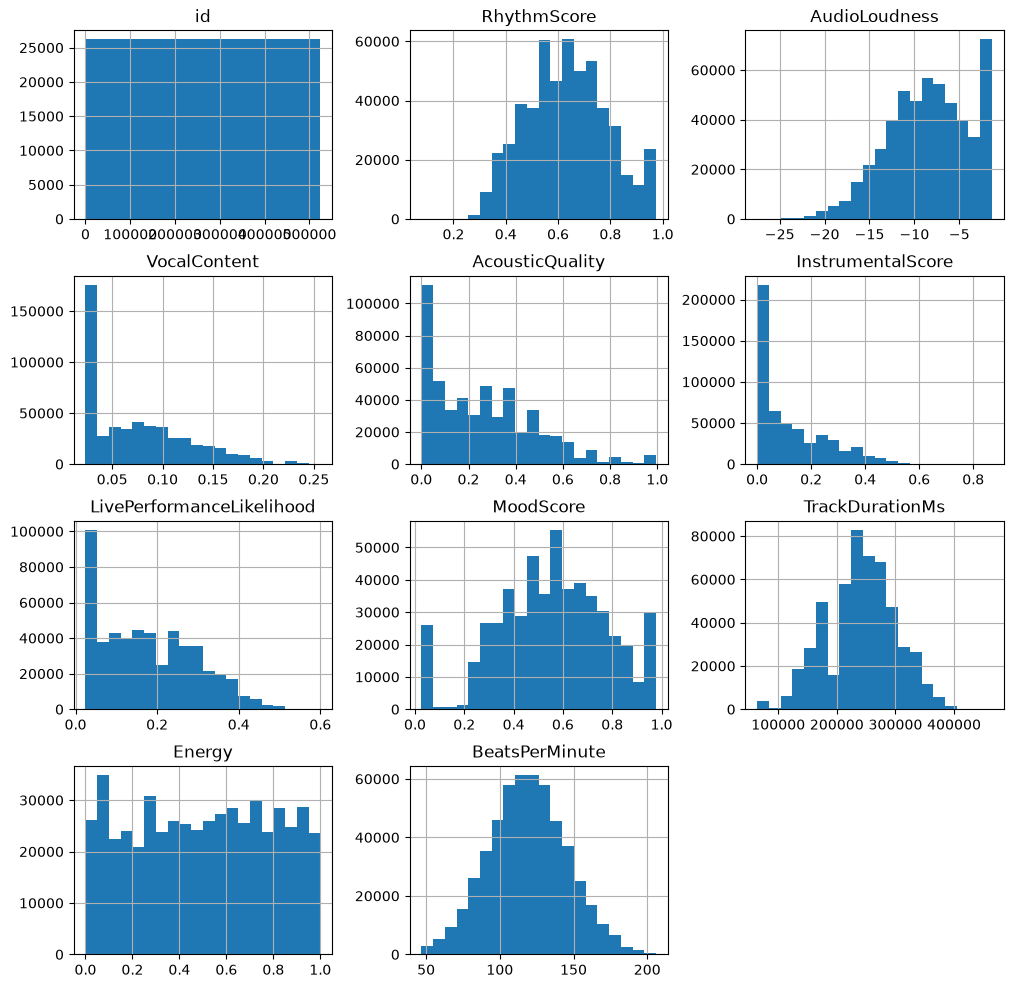

In [8]:
# Histograma de todas las variables numéricas
data.hist(figsize=(12, 12), bins=20)
plt.show()

>La distribución de los datos nos permite ver que todas las variables tienden a agrupar la mayoría de los valores en un rango específico.

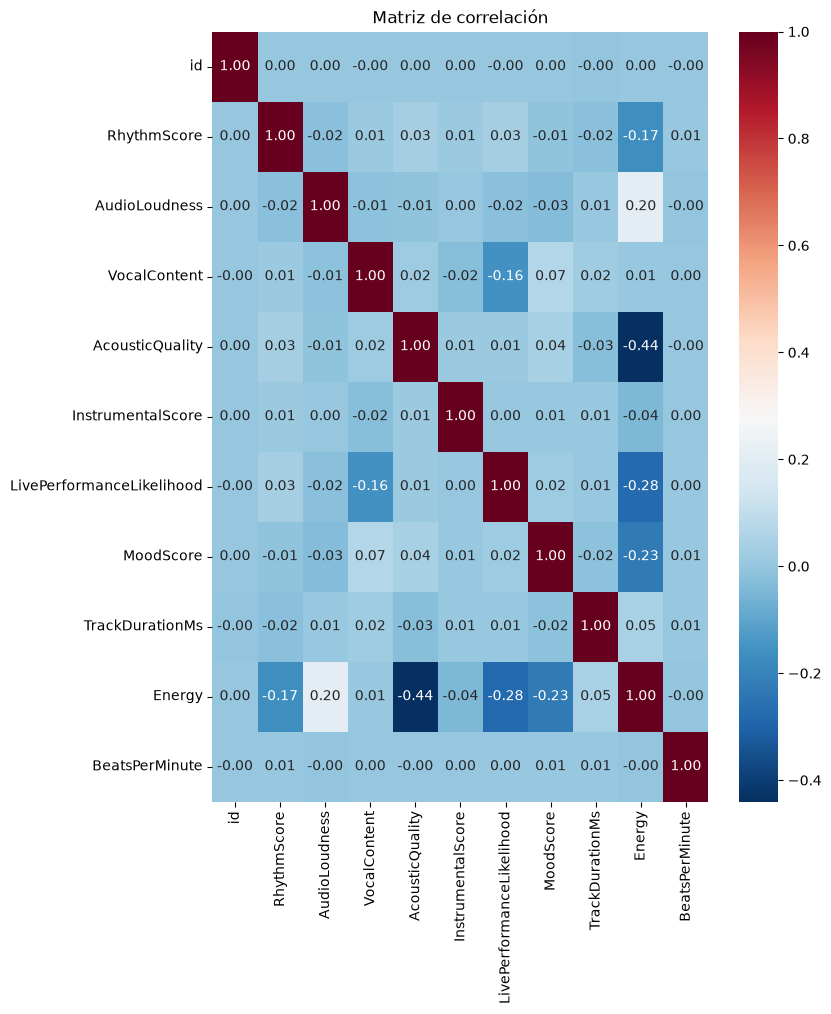

In [9]:
# Visualización de la correlación entre variables
plt.figure(figsize=(8, 10))
sns.heatmap(data.corr(method="spearman"), annot=True, fmt='.2f', cmap='RdBu_r')
plt.title('Matriz de correlación')
plt.show()

In [10]:
# Análisis de parejas de variables más correladas entre sí
correlation_matrix = data.corr()
corr_pairs = correlation_matrix.abs().unstack().sort_values(kind="quicksort", ascending=False).reset_index()
corr_pairs.columns = ['Variable 1', 'Variable 2', 'Correlación']
corr_pairs = corr_pairs[corr_pairs['Variable 1'] != corr_pairs['Variable 2']]
print(corr_pairs.head(20))

                   Variable 1                 Variable 2  Correlación
11            AcousticQuality                     Energy     0.418184
12                     Energy            AcousticQuality     0.418184
13  LivePerformanceLikelihood                     Energy     0.266256
14                     Energy  LivePerformanceLikelihood     0.266256
15                  MoodScore                     Energy     0.241713
16                     Energy                  MoodScore     0.241713
17                     Energy              AudioLoudness     0.192411
18              AudioLoudness                     Energy     0.192411
19                RhythmScore                     Energy     0.147350
20                     Energy                RhythmScore     0.147350
21  LivePerformanceLikelihood               VocalContent     0.120294
22               VocalContent  LivePerformanceLikelihood     0.120294
23               VocalContent                  MoodScore     0.058675
24                  

>Energy tiene relación con las variables AcousticQuality, LivePerformanceLikelihood y MoodScore.  Las demás variables tienen poca relación lineal entre sí.

In [11]:
#Evaluación de correlación mutua entre las variables y la variable objetivo
var1 = data.drop(columns="BeatsPerMinute")
var2 = data["BeatsPerMinute"]
mutua = mutual_info_regression(var1, var2, random_state=42)

In [12]:
#Verificación de los datos de la relación mutua
mutua_result = pd.Series(mutua, index=var1.columns).sort_values(ascending=False)
print(mutua_result)

VocalContent                 0.002880
AcousticQuality              0.001291
Energy                       0.001239
id                           0.000886
LivePerformanceLikelihood    0.000848
RhythmScore                  0.000664
TrackDurationMs              0.000353
MoodScore                    0.000112
InstrumentalScore            0.000000
AudioLoudness                0.000000
dtype: float64


In [13]:
# Variables más correladas con la variable objetivo
target_corr = correlation_matrix['BeatsPerMinute'].abs().sort_values(ascending=False).reset_index()
target_corr.columns = ['Variable', 'Correlación con BeatsPerMinute(Target)']
print(target_corr)

                     Variable  Correlación con BeatsPerMinute(Target)
0              BeatsPerMinute                                1.000000
1                   MoodScore                                0.007059
2             TrackDurationMs                                0.006637
3                 RhythmScore                                0.005440
4                VocalContent                                0.004876
5                      Energy                                0.004375
6   LivePerformanceLikelihood                                0.003471
7               AudioLoudness                                0.003327
8           InstrumentalScore                                0.001900
9             AcousticQuality                                0.000820
10                         id                                0.000355


>La correlación mutua entre las variables de entrada y la variable target es muy baja.

**Resumen Análisis de los Datos**

>Todas las variables son numéricas o categoricas ya representadas de manera numérica y la mayoría ya están escaladas por lo que no se va a realizar otro ajustesobre esas variables.
>
>La correlación lineal entre las varibles, incluída la variable objetivo es leve, por eso se evalúa a correlación mutua buscando algún tipo de parámetro, pero se llega al mismo resultado, la correlación es muy baja.
>
>Al estar las variables escaladas no se ve outliners que puedan afectar el rendimiento del modelo y en las variables que no están escaladas tampoco se evidencia, en la dispersión de los valores se ve que se agrupan a lo largo de un rango.
>
>Los valores de las variables TrackDurationMS y AudioLoudness se escalaron para ser usadas en un modelo de regresión y así permitir que el modelo funcione de una mejor manera.
>
>Como las correlación, en general, entre las variables y la variable objetivo es baja, se va a usar un modelo de regresión lineal y tomarlo como base.  Este modelo permite predecir valores continuos de la variable objetivo, como es en este caso BeatsPerMinute.

**Modelo de Regresión Lineal**

>Se escoge el modelo de regresión lineal porque la distribución de la variable BeatsPerSecond(target) tiene valores continuos en un randgo específico y la regresión lineal puede permitir realizar la predicción de una manera ajustada.

Mejor modelo: {'fit_intercept': True}
MSE: 699.8067835555283, 
RMSE: 26.453861411059226, 
R^2: 0.0001348277722758029


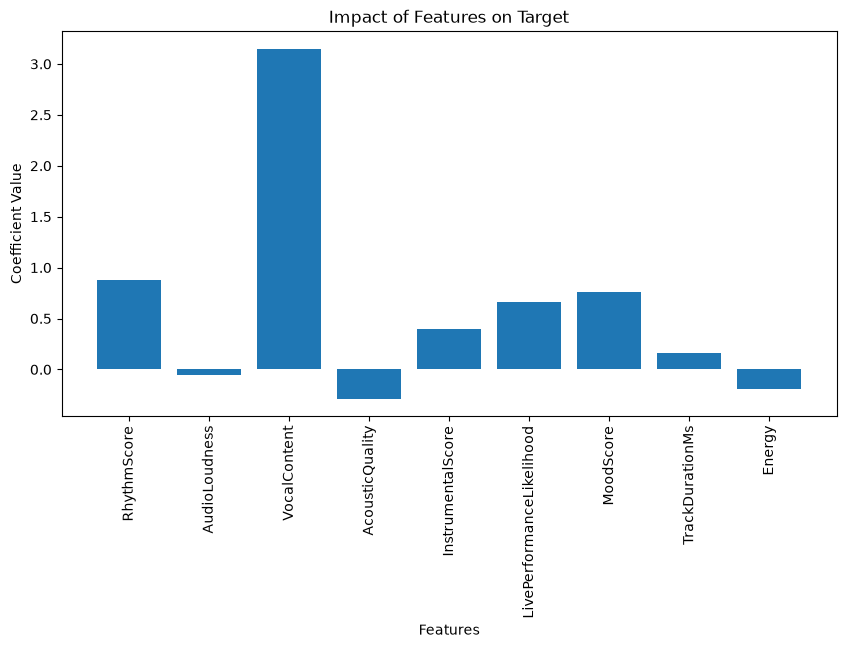

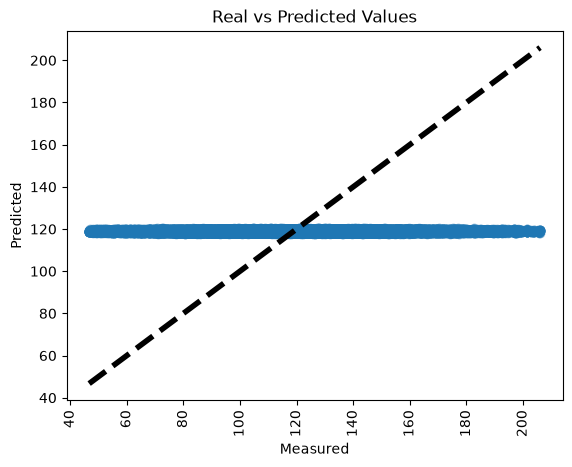

In [14]:
# Separación del conjuto de datos y estandarización de las variables TrackDurationMS y BeatsPerSecond


X = data.drop(columns=["id", "BeatsPerMinute"])
y = data["BeatsPerMinute"]

#Separación de los datos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

#escalado de las variables faltantes
columnas_escalar = ["AudioLoudness", "TrackDurationMs", ]
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_train_scaled[columnas_escalar] = scaler.fit_transform(X_train[columnas_escalar])
X_test_scaled = X_test.copy()
X_test_scaled[columnas_escalar] = scaler.transform(X_test[columnas_escalar])

#Modelo de regresión lineal con grid search
# Modelo y grid search
model = LinearRegression()
params = {'fit_intercept': [True, False]}
grid_search = GridSearchCV(model, params, cv=10, scoring=make_scorer(mean_squared_error, greater_is_better=False))
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_

# Predicciones y evaluación
y_pred = best_model.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"Mejor modelo: {grid_search.best_params_}")
print(f"MSE: {mse}, \nRMSE: {rmse}, \nR^2: {r2}")


#Datos del mejor modelo
coefficients = best_model.coef_
features = X.columns

plt.figure(figsize=(10, 5))
plt.bar(features, coefficients)
plt.xlabel('Features')
plt.ylabel('Coefficient Value')
plt.title('Impact of Features on Target')
plt.xticks(rotation=90)
plt.show()

# Visualización de las Predicciones vs. Valores Reales
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=4)
plt.xlabel('Measured')
plt.ylabel('Predicted')
plt.title('Real vs Predicted Values')
plt.xticks(rotation=90)
plt.show()



In [15]:
#Pipeline y configuración del Modelo
pipeline = Pipeline(
    steps=[
        ("polinomios", PolynomialFeatures(degree=3, include_bias=False)),
        ("modelo", LinearRegression())
      ]
)
 
# Entrenamiento del modelo
pipeline.fit(X_train_scaled, y_train)
 
# Predicción
y_pred_pol = pipeline.predict(X_test_scaled)
 
# Evaluación y métricas
mse = mean_squared_error(y_test, y_pred_pol)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred_pol)
r2 = r2_score(y_test, y_pred_pol)
 
print(f"MSE : {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE : {mae:.2f}")
print(f"R²  : {r2:.3f}")

MSE : 699.99
RMSE: 26.46
MAE : 21.19
R²  : -0.000


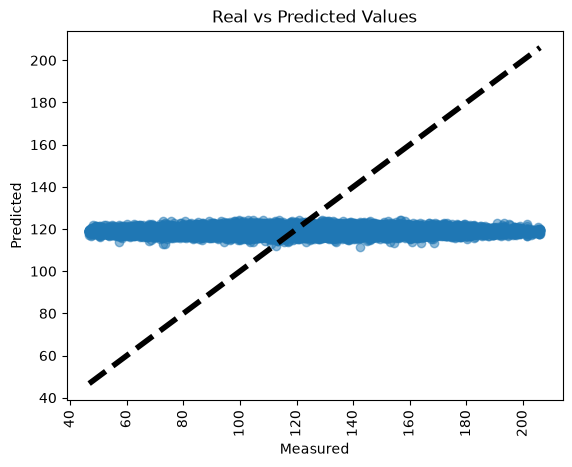

In [16]:
# Visualización de las Predicciones vs. Valores Reales
plt.scatter(y_test, y_pred_pol, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=4)
plt.xlabel('Measured')
plt.ylabel('Predicted')
plt.title('Real vs Predicted Values')
plt.xticks(rotation=90)
plt.show()

In [17]:
#Pipeline y configuración del Modelo
modelo_xgb = XGBRegressor(
    n_estimators=900,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)
 
# Entrenamiento del modelo
modelo_xgb.fit(X_train_scaled, y_train)
 
# Predicción
y_pred_xgb = modelo_xgb.predict(X_test_scaled)
 
# Evaluación y métricas
mse = mean_squared_error(y_test, y_pred_xgb)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred_xgb)
r2 = r2_score(y_test, y_pred)
 
print(f"[XGBoost] MSE : {mse:.2f}")
print(f"[XGBoost] RMSE: {rmse:.2f}")
print(f"[XGBoost] MAE : {mae:.2f}")
print(f"[XGBoost] R²  : {r2:.3f}")

[XGBoost] MSE : 701.88
[XGBoost] RMSE: 26.49
[XGBoost] MAE : 21.22
[XGBoost] R²  : 0.000


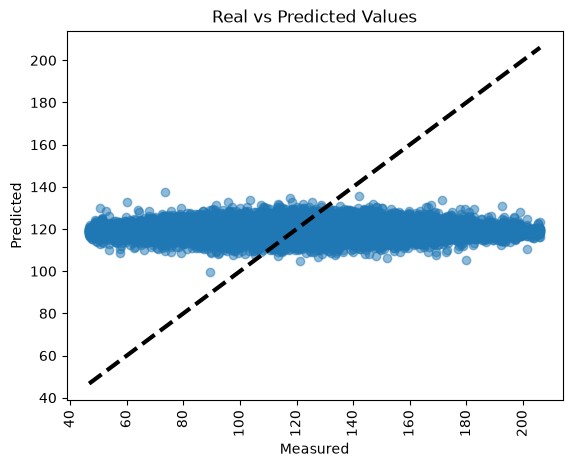

In [18]:
# Visualización de las Predicciones vs. Valores Reales
plt.scatter(y_test, y_pred_xgb, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=3)
plt.xlabel('Measured')
plt.ylabel('Predicted')
plt.title('Real vs Predicted Values')
plt.xticks(rotation=90)
plt.show()

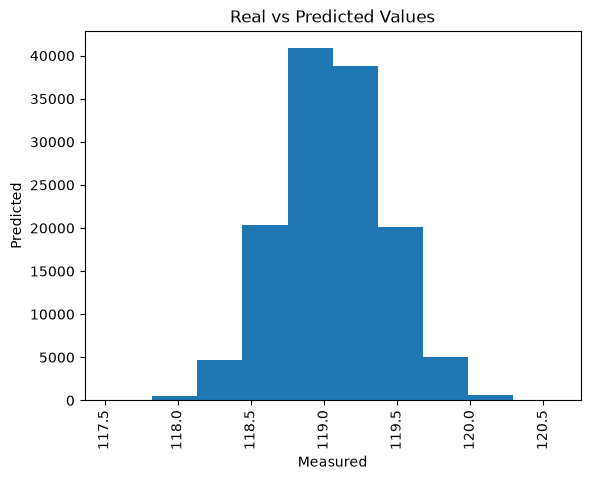

In [19]:
#grafico de los datos que predice el modelo
plt.hist(y_pred)
#plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=3)
plt.xlabel('Measured')
plt.ylabel('Predicted')
plt.title('Real vs Predicted Values')
plt.xticks(rotation=90)
plt.show()

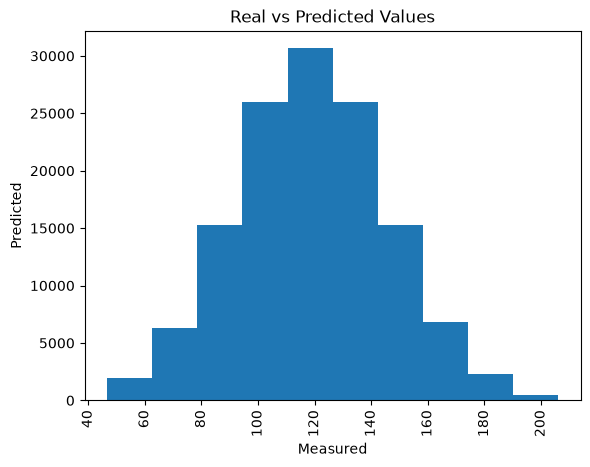

In [20]:
#grafico de los datos qde la variable objetivo del conjunto de test
plt.hist(y_test)
#plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=3)
plt.xlabel('Measured')
plt.ylabel('Predicted')
plt.title('Real vs Predicted Values')
plt.xticks(rotation=90)
plt.show()

In [21]:
#Pipeline y configuración del Modelo
modelo_rfr = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,

    min_samples_leaf=3,
    n_jobs=-1,
    random_state=42
)
 
# 4. Entrenamiento del modelo
modelo_rfr.fit(X_train, y_train)
 
# 5. Predicción
y_pred_rfr = modelo_rfr.predict(X_test)
 
# 6. Evaluación y métricas
mse = mean_squared_error(y_test, y_pred_rfr)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred_rfr)
r2 = r2_score(y_test, y_pred_rfr)
 
print(f"[Random Forest] MSE : {mse:.2f}")
print(f"[Random Forest] RMSE: {rmse:.2f}")
print(f"[Random Forest] MAE : {mae:.2f}")
print(f"[Random Forest] R²  : {r2:.3f}")

[Random Forest] MSE : 706.32
[Random Forest] RMSE: 26.58
[Random Forest] MAE : 21.29
[Random Forest] R²  : -0.009


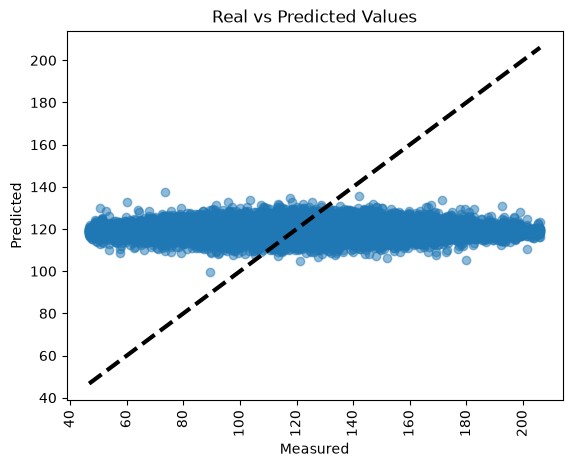

In [23]:
# Visualización de las Predicciones vs. Valores Reales
plt.scatter(y_test, y_pred_xgb, alpha=0.5)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=3)
plt.xlabel('Measured')
plt.ylabel('Predicted')
plt.title('Real vs Predicted Values')
plt.xticks(rotation=90)
plt.show()